<a href="https://colab.research.google.com/github/RAHMAH099/Computer_vision_cats_vs_dogs_CNN/blob/main/Practice_in_Computer_Vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Computer Vision

In NLP you turned **text** into numbers and trained models on it. In computer vision the input is an **image**, and an image is already numbers.


1. Load an image dataset
2. See that an image is just a grid of numbers
3. Look at colour images and their 3 channels
4. Prepare images for a model
5. Apply a filter by hand (this is what a CNN does)
6. Train a **Dense** neural network (baseline)
7. Train a **CNN** and compare
8. Study the mistakes
9. Look inside the CNN

> ⚙️ **Before you start:** Runtime → Change runtime type → **T4 GPU** → Save.

## 0 · Imports

In [1]:
from datasets import load_dataset

ds = load_dataset("microsoft/cats_vs_dogs")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scipy.signal import correlate2d
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)
print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available: True


## 1 · Load the data




In [3]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("microsoft/cats_vs_dogs")
print(ds)

names = ds["train"].features["labels"].names
print(names)   # ['cat', 'dog']

split = ds["train"].train_test_split(test_size=0.2, seed=42, stratify_by_column="labels")
train_ds, test_ds = split["train"], split["test"]
print(len(train_ds), len(test_ds))

df = train_ds.remove_columns("image").to_pandas()
df["label_name"] = df["labels"].map(lambda i: names[i])
df["label_name"].value_counts()

DatasetDict({
    train: Dataset({
        features: ['image', 'labels'],
        num_rows: 23410
    })
})
['cat', 'dog']
18728 4682


,count
label_name,
cat,9393
dog,9335


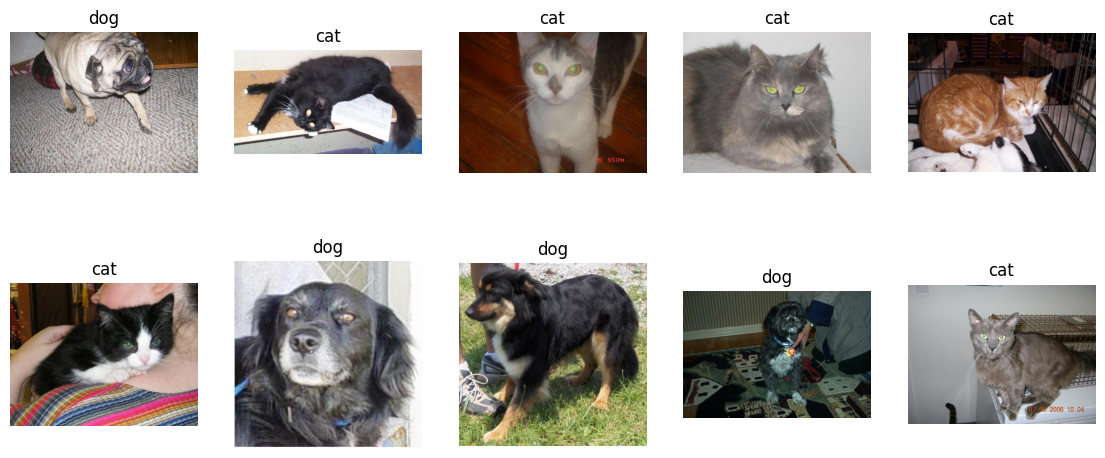

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, i in zip(axes.flat, range(10)):
    ax.imshow(train_ds[i]["image"])
    ax.set_title(names[train_ds[i]["labels"]])
    ax.axis("off")
plt.show()

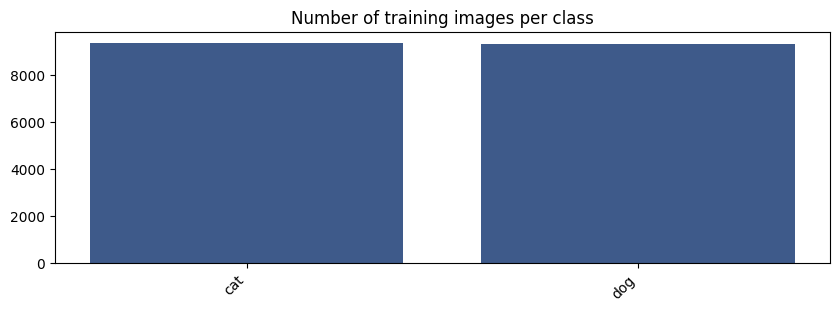

In [5]:
class_names = names

counts = np.bincount(train_ds["labels"])
plt.figure(figsize=(10, 3))
plt.bar(class_names, counts, color="#3E5A8A")
plt.xticks(rotation=45, ha="right")
plt.title("Number of training images per class")
plt.show()

In [6]:
import numpy as np

SIZE = 64

def to_arrays(split):
    X, y = [], []
    for ex in split:
        try:
            im = ex["image"].convert("RGB").resize((SIZE, SIZE))
            X.append(np.array(im, dtype="uint8"))
            y.append(ex["labels"])
        except Exception:
            continue
    return np.stack(X), np.array(y)

X_train, y_train = to_arrays(train_ds)
X_test, y_test = to_arrays(test_ds)
print(X_train.shape, X_test.shape)

(18728, 64, 64, 3) (4682, 64, 64, 3)


## 2 · An image is a grid of numbers



In [7]:
for v in ["ds", "train_ds", "test_ds", "names", "X_train", "y_train"]:
    print(v, v in globals())

ds True
train_ds True
test_ds True
names True
X_train True
y_train True


In [8]:
image = X_train[0]
print("Shape:", image.shape)
print("Data type:", image.dtype)
print("Smallest value:", image.min(), " Largest value:", image.max())

np.set_printoptions(linewidth=200)
print(image[:10, :10, 0])   # top-left 10x10 pixels, red channel

Shape: (64, 64, 3)
Data type: uint8
Smallest value: 1  Largest value: 253
[[112 120 122 126 129 130 134 136 105  68]
 [116 122 127 128 131 133 136 140 137  77]
 [117 122 127 130 135 137 140 143 142 133]
 [118 123 128 132 137 143 143 144 145 145]
 [121 126 130 133 137 144 145 146 147 144]
 [125 128 130 133 138 144 147 145 147 146]
 [127 130 132 136 140 143 144 145 147 148]
 [128 132 134 138 140 144 146 148 149 154]
 [129 133 137 138 142 151 151 151 152 154]
 [132 135 136 141 146 150 150 153 155 155]]


## 3 · Colour images have 3 channels



Shape: (64, 64, 3) → (height, width, channels)
Total numbers in this image: 12288
The top-left pixel (R, G, B): [112 111 114]


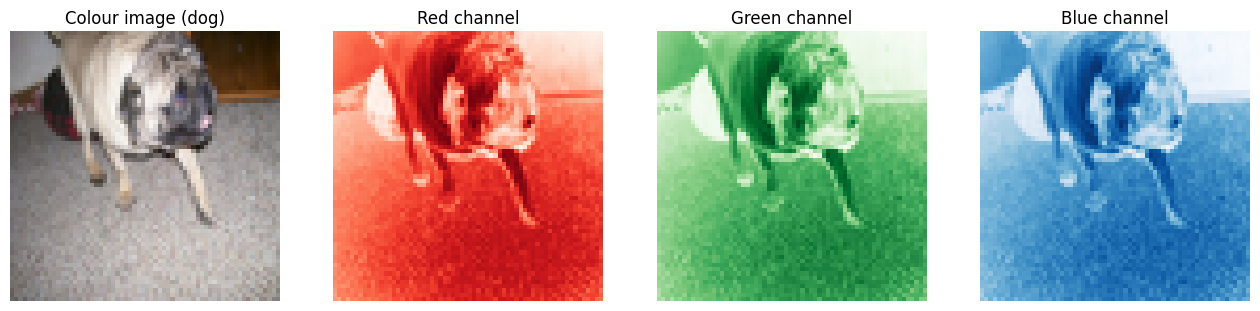

In [9]:
img = X_train[0]   # one photo from our cats vs dogs data

print("Shape:", img.shape, "→ (height, width, channels)")
print("Total numbers in this image:", img.size)
print("The top-left pixel (R, G, B):", img[0, 0])

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img)
axes[0].set_title(f"Colour image ({names[y_train[0]]})")
for i, (name, cmap) in enumerate([("Red", "Reds"), ("Green", "Greens"), ("Blue", "Blues")]):
    axes[i + 1].imshow(img[:, :, i], cmap=cmap)
    axes[i + 1].set_title(f"{name} channel")
for ax in axes:
    ax.axis("off")
plt.show()

Grayscale shape: (64, 64)


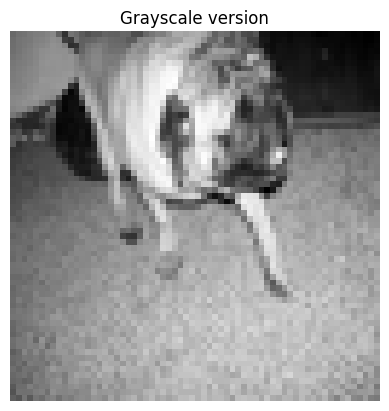

In [10]:
# Turning colour into grayscale = combining the 3 channels into 1
gray_img = img.mean(axis=2)
print("Grayscale shape:", gray_img.shape)
plt.imshow(gray_img, cmap="gray")
plt.title("Grayscale version")
plt.axis("off")
plt.show()

## 4 · Prepare the images

Two steps, like cleaning text in NLP:
1. **Normalise**: divide by 255 so every value is between 0 and 1.
2. **Add a channel dimension**: Keras CNNs expect `(height, width, channels)`. Grayscale has 1 channel, so `(28, 28)` becomes `(28, 28, 1)`.

We also keep 10% of the training data aside as a **validation set**.

In [11]:
X_train_norm = X_train.astype("float32") / 255.0
X_test_norm = X_test.astype("float32") / 255.0

print("Train:", X_train_norm.shape, " min:", X_train_norm.min(), " max:", X_train_norm.max())
print("Test: ", X_test_norm.shape)

Train: (18728, 64, 64, 3)  min: 0.0  max: 1.0
Test:  (4682, 64, 64, 3)


## 5 · Apply a filter by hand

A **filter** (or kernel) is a small grid of numbers. We slide it over the image; at each position we multiply and add. The result is a **feature map** that lights up where the filter's pattern appears.

This is exactly what a `Conv2D` layer does, except a CNN **learns** its own filter numbers during training.

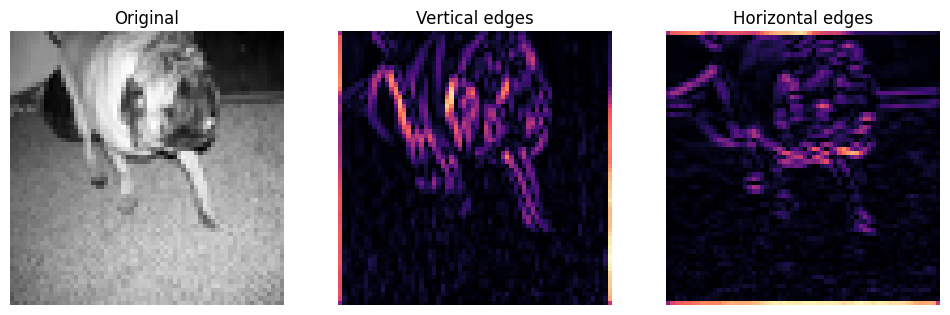

In [12]:
vertical_edge = np.array([[-1, 0, 1],
                          [-1, 0, 1],
                          [-1, 0, 1]])

horizontal_edge = np.array([[-1, -1, -1],
                            [ 0,  0,  0],
                            [ 1,  1,  1]])

sample = X_train_norm[0].mean(axis=2)   # one image, 128 x 128 (colour averaged to grayscale)

vertical_map = correlate2d(sample, vertical_edge, mode="same")
horizontal_map = correlate2d(sample, horizontal_edge, mode="same")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(sample, cmap="gray"); axes[0].set_title("Original")
axes[1].imshow(np.abs(vertical_map), cmap="magma"); axes[1].set_title("Vertical edges")
axes[2].imshow(np.abs(horizontal_map), cmap="magma"); axes[2].set_title("Horizontal edges")
for ax in axes:
    ax.axis("off")
plt.show()

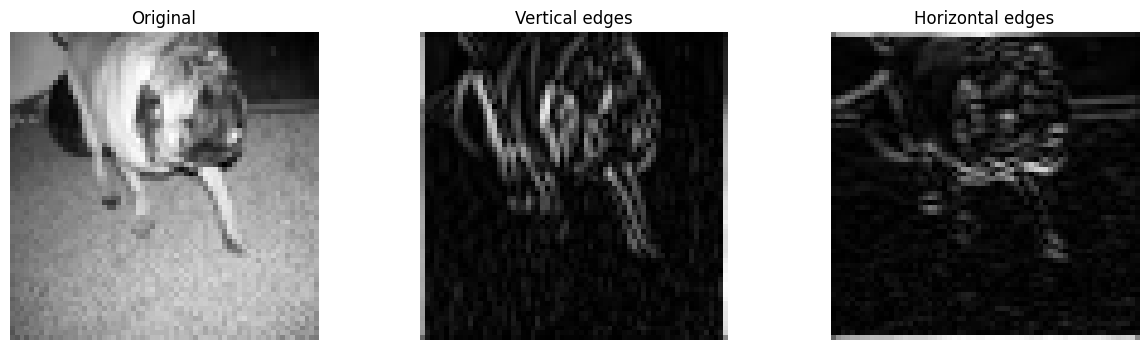

In [13]:
# Try it on the colour photo's grayscale version: edges are clearer on a big image
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(gray_img, cmap="gray"); axes[0].set_title("Original")
axes[1].imshow(np.abs(correlate2d(gray_img, vertical_edge, mode="same")), cmap="gray"); axes[1].set_title("Vertical edges")
axes[2].imshow(np.abs(correlate2d(gray_img, horizontal_edge, mode="same")), cmap="gray"); axes[2].set_title("Horizontal edges")
for ax in axes:
    ax.axis("off")
plt.show()

## 6 · Model 1: Dense neural network (baseline)



In [14]:
dense_model = keras.Sequential([
    layers.Input(shape=(64, 64, 3)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(2, activation="softmax"),    # 2 classes (cat, dog) -> 2 outputs
])

dense_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",   # labels are whole numbers 0-1
    metrics=["accuracy"],
)
dense_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,573,250 (6.00 MB)

 Trainable params: 1,573,250 (6.00 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
dense_history = dense_model.fit(
    X_train_norm, y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=64,
)

Epoch 1/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.5459 - loss: 0.8976 - val_accuracy: 0.5590 - val_loss: 0.7189
Epoch 2/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5840 - loss: 0.6966 - val_accuracy: 0.5537 - val_loss: 0.7570
Epoch 3/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5955 - loss: 0.6815 - val_accuracy: 0.5424 - val_loss: 0.8109
Epoch 4/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6077 - loss: 0.6628 - val_accuracy: 0.6044 - val_loss: 0.6464
Epoch 5/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6155 - loss: 0.6529 - val_accuracy: 0.6076 - val_loss: 0.6490
Epoch 6/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6273 - loss: 0.6441 - val_accuracy: 0.6204 - val_loss: 0.6445
Epoch 7/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6312 - loss: 0.6402 - val_accuracy: 0.6140 - val_loss: 0.6464
Epoch 8/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6375 - loss: 0.6360 - val_accuracy: 0

In [19]:
dense_loss, dense_acc = dense_model.evaluate(X_test_norm, y_test, verbose=0)
print(f"Dense model test accuracy: {dense_acc:.4f}")

Dense model test accuracy: 0.5991


## 7 · Model 2: Convolutional Neural Network (CNN)

Same Keras `Sequential` style. The new layers are:
- `Conv2D(32, (3, 3))`: learns **32 filters**, each 3 × 3, like the ones you made by hand.
- `MaxPooling2D((2, 2))`: shrinks the feature maps by half, keeping the strongest value in each 2 × 2 area.

Then `Flatten` and `Dense` layers make the final decision, exactly as before.

In [20]:
cnn_model = keras.Sequential([
    layers.Input(shape=(64, 64, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(2, activation="softmax"),
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
cnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 822,402 (3.14 MB)

 Trainable params: 822,402 (3.14 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
cnn_history = cnn_model.fit(
    X_train_norm, y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=64,
)

Epoch 1/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - accuracy: 0.6685 - loss: 0.6068 - val_accuracy: 0.7336 - val_loss: 0.5577
Epoch 2/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7547 - loss: 0.4999 - val_accuracy: 0.7213 - val_loss: 0.5552
Epoch 3/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.7902 - loss: 0.4470 - val_accuracy: 0.7854 - val_loss: 0.4919
Epoch 4/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8198 - loss: 0.3953 - val_accuracy: 0.7608 - val_loss: 0.5408
Epoch 5/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8415 - loss: 0.3575 - val_accuracy: 0.7763 - val_loss: 0.5010
Epoch 6/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8691 - loss: 0.3084 - val_accuracy: 0.7806 - val_loss: 0.5156
Epoch 7/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8953 - loss: 0.2531 - val_accuracy: 0.7779 - val_loss: 0.5794
Epoch 8/10
264/264 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9130 - loss: 0.2171 - val_accurac

In [22]:
cnn_loss, cnn_acc = cnn_model.evaluate(X_test_norm, y_test, verbose=0)
print(f"Dense model test accuracy: {dense_acc:.4f}")
print(f"CNN model test accuracy:   {cnn_acc:.4f}")

Dense model test accuracy: 0.5991
CNN model test accuracy:   0.7836


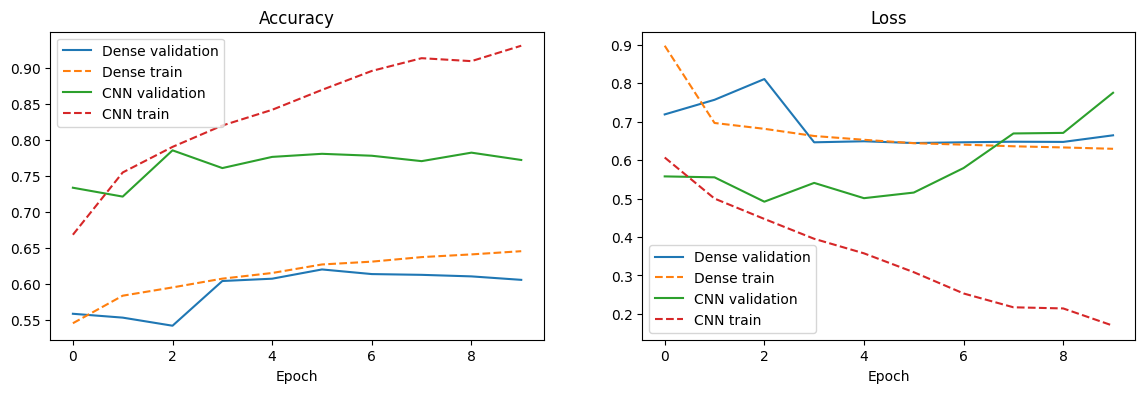

In [23]:
# Compare the training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for history, name in [(dense_history, "Dense"), (cnn_history, "CNN")]:
    axes[0].plot(history.history["val_accuracy"], label=f"{name} validation")
    axes[0].plot(history.history["accuracy"], linestyle="--", label=f"{name} train")
    axes[1].plot(history.history["val_loss"], label=f"{name} validation")
    axes[1].plot(history.history["loss"], linestyle="--", label=f"{name} train")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.show()

## 8 · Evaluate the CNN in detail

In [24]:
probs = cnn_model.predict(X_test_norm)
y_pred = probs.argmax(axis=1)   # the class with the highest probability

print(classification_report(y_test, y_pred, target_names=class_names))

147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
              precision    recall  f1-score   support

         cat       0.83      0.71      0.77      2348
         dog       0.75      0.86      0.80      2334

    accuracy                           0.78      4682
   macro avg       0.79      0.78      0.78      4682
weighted avg       0.79      0.78      0.78      4682



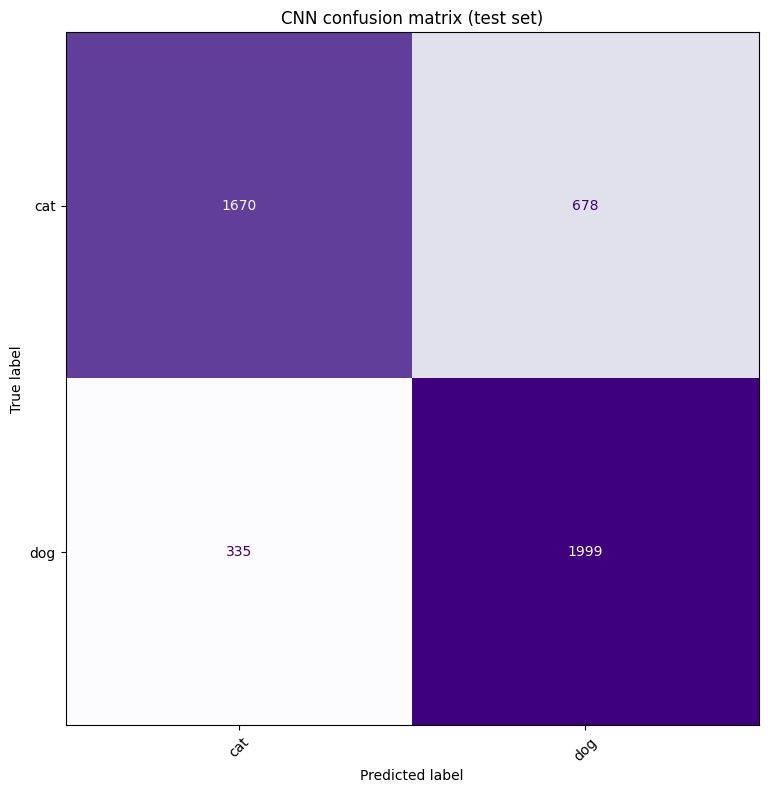

In [25]:
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, xticks_rotation=45,
    cmap="Purples", colorbar=False, ax=ax,
)
ax.set_title("CNN confusion matrix (test set)")
plt.show()

💬 **Discuss:** Which two classes does the model confuse most? Does that make sense to a human?

1013 mistakes out of 4682 test images


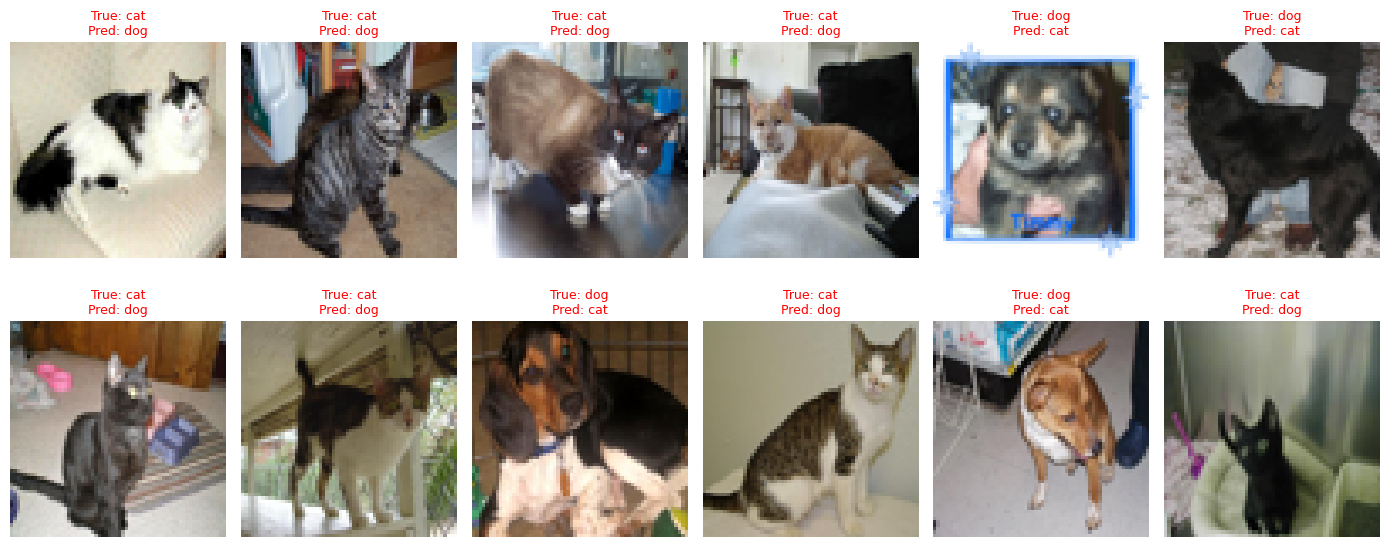

In [26]:
# Show some mistakes
wrong = np.where(y_pred != y_test)[0]
print(f"{len(wrong)} mistakes out of {len(y_test)} test images")

plt.figure(figsize=(14, 6))
for i, idx in enumerate(wrong[:12]):
    plt.subplot(2, 6, i + 1)
    plt.imshow(X_test[idx])
    plt.title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=9, color="red")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 9 · Look inside the CNN

What did the first `Conv2D` layer learn? Below are its **feature maps** for one image: each of the 32 small pictures is what one learned filter "sees".

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Feature maps shape: (1, 62, 62, 32)


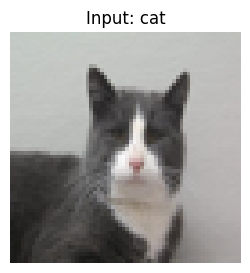

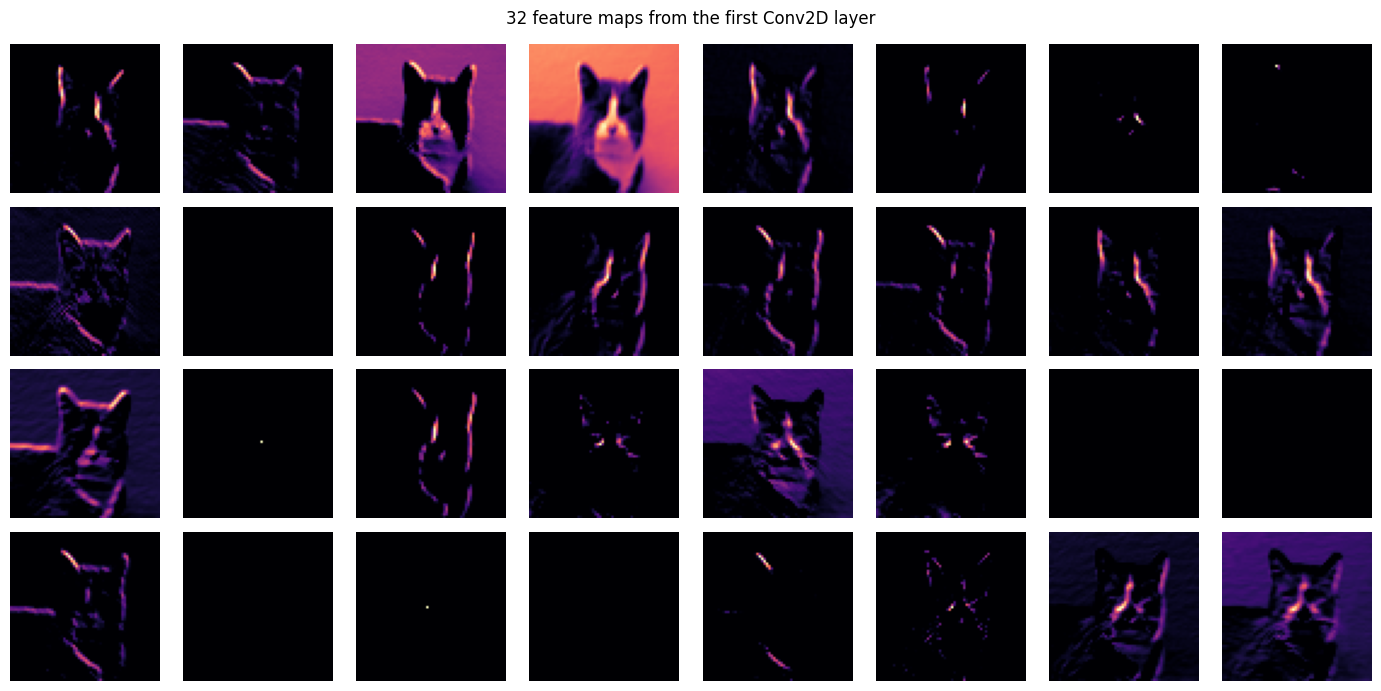

In [27]:
first_conv = keras.Model(inputs=cnn_model.inputs, outputs=cnn_model.layers[0].output)

idx = 0
feature_maps = first_conv.predict(X_test_norm[idx:idx + 1])
print("Feature maps shape:", feature_maps.shape)   # (1, 62, 62, 32)

plt.figure(figsize=(3, 3))
plt.imshow(X_test[idx])
plt.title(f"Input: {class_names[y_test[idx]]}")
plt.axis("off")
plt.show()

plt.figure(figsize=(14, 7))
for i in range(32):
    plt.subplot(4, 8, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap="magma")
    plt.axis("off")
plt.suptitle("32 feature maps from the first Conv2D layer")
plt.tight_layout()
plt.show()

💡 Some maps highlight edges, some the outline, some the background. The model learned these filters by itself.

## 10 · Predict a single image

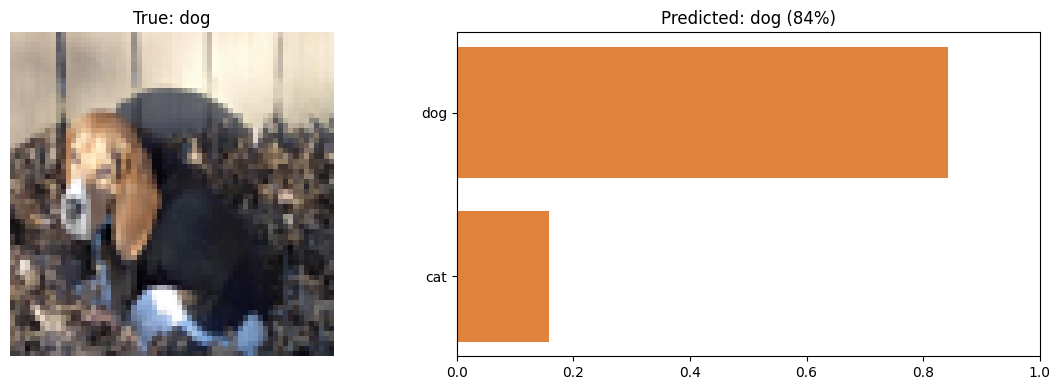

In [28]:
idx = 25   # change this number to try other test images

p = cnn_model.predict(X_test_norm[idx:idx + 1], verbose=0)[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(X_test[idx])
axes[0].set_title(f"True: {class_names[y_test[idx]]}")
axes[0].axis("off")
axes[1].barh(class_names, p, color="#E0823C")
axes[1].set_xlim(0, 1)
axes[1].set_title(f"Predicted: {class_names[p.argmax()]} ({p.max():.0%})")
plt.tight_layout()
plt.show()

In [29]:
cnn_model.save("cats_vs_dogs_cnn.keras")

In [30]:
from huggingface_hub import notebook_login
notebook_login()

In [32]:
from huggingface_hub import HfApi

api = HfApi()
repo_id = "RahmahwithCode/cats-vs-dogs-cnn"

api.create_repo(repo_id=repo_id, repo_type="model", exist_ok=True)
api.upload_file(
    path_or_fileobj="cats_vs_dogs_cnn.keras",
    path_in_repo="cats_vs_dogs_cnn.keras",
    repo_id=repo_id,
)
print("Uploaded: https://huggingface.co/" + repo_id)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...nt/cats_vs_dogs_cnn.keras:   6%|5         |  578kB / 9.91MB            

Validating                    :           |   0%            

Uploaded: https://huggingface.co/RahmahwithCode/cats-vs-dogs-cnn


In [33]:
readme = """---
tags:
- image-classification
- keras
- computer-vision
datasets:
- microsoft/cats_vs_dogs
metrics:
- accuracy
---

# Cats vs Dogs CNN

A small convolutional neural network (Keras) that classifies photos as cat or dog.

- Trained on microsoft/cats_vs_dogs
- Input: RGB images resized to 64x64, pixel values divided by 255
- Classes: 0 = cat, 1 = dog
- Test accuracy: 0.78

## Use
```python
from tensorflow import keras
model = keras.models.load_model("cats_vs_dogs_cnn.keras")
```
"""

with open("README.md", "w") as f:
    f.write(readme)

api.upload_file(path_or_fileobj="README.md", path_in_repo="README.md", repo_id=repo_id)

CommitInfo(commit_url='https://huggingface.co/RahmahwithCode/cats-vs-dogs-cnn/commit/0c54f935c7632109936da45b1e1fac4264a1a113', commit_message='Upload README.md with huggingface_hub', commit_description='', oid='0c54f935c7632109936da45b1e1fac4264a1a113', pr_url=None, repo_url=RepoUrl('https://huggingface.co/RahmahwithCode/cats-vs-dogs-cnn', endpoint='https://huggingface.co', repo_type='model', repo_id='RahmahwithCode/cats-vs-dogs-cnn'), pr_revision=None, pr_num=None)

---
## ✅ Summary

| Step | What you did |
|---|---|
| Load | `keras.datasets.fashion_mnist.load_data()` |
| Explore | Shapes, classes, pixel values (0–255) |
| Colour | 3 channels: Red, Green, Blue |
| Prepare | Normalise (÷ 255) and add a channel dimension |
| Filters | Applied edge filters by hand |
| Dense model | Flatten + Dense (baseline) |
| CNN | Conv2D + MaxPooling2D + Dense |
| Evaluate | Accuracy, classification report, confusion matrix, mistakes |

## 📝 Your task
Change **one thing** in the CNN, re-train it, and record the test accuracy before and after in a text cell:
- More filters: `Conv2D(64, ...)` in the first layer
- Add `layers.Dropout(0.3)` after the `Dense(64)` layer
- Train for 15 epochs instead of 10
- Remove one `Conv2D` + `MaxPooling2D` pair

Explain in one or two sentences why you think the accuracy changed.